In [3]:
%pip install -q importlib_resources


In [1]:
import tensorflow as tf

print("Version de TensorFlow:", tf.__version__)
print("GPU disponibles:",
      tf.config.list_physical_devices("GPU"))


Version de TensorFlow: 2.21.0
GPU disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
!pip -q install tensorflow-datasets

import tensorflow_datasets as tfds

datos = tfds.load(
    "cats_vs_dogs",
    split="train",
    as_supervised=True
)

print("Dataset cargado correctamente")


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.ERS8KD_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
Dataset cargado correctamente


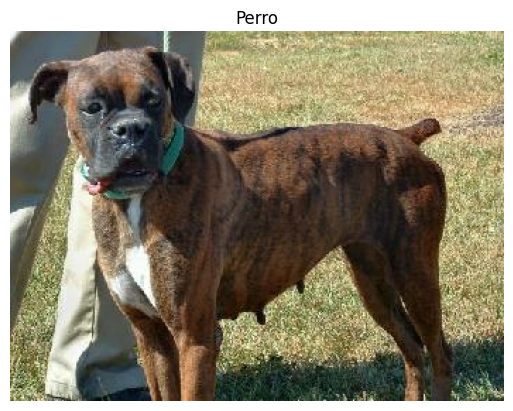

In [5]:

import matplotlib.pyplot as plt

for imagen, etiqueta in datos.take(1):
    plt.imshow(imagen.numpy())
    plt.title(
        "Perro" if etiqueta.numpy() == 1 else "Gato"
    )
    plt.axis("off")
    plt.show()


In [6]:

import tensorflow as tf

# Separar gatos y perros
gatos = datos.filter(
    lambda imagen, etiqueta: tf.equal(etiqueta, 0)
).take(1000)

perros = datos.filter(
    lambda imagen, etiqueta: tf.equal(etiqueta, 1)
).take(1000)

# Dividir cada grupo
def dividir(grupo):
    entrenamiento = grupo.take(700)
    validacion = grupo.skip(700).take(150)
    prueba = grupo.skip(850).take(150)
    return entrenamiento, validacion, prueba

g_ent, g_val, g_pru = dividir(gatos)
p_ent, p_val, p_pru = dividir(perros)

# Combinar ambas categorias
train = g_ent.concatenate(p_ent)
val = g_val.concatenate(p_val)
test = g_pru.concatenate(p_pru)

print("Datos divididos correctamente")
print("Entrenamiento: 1400")
print("Validacion: 300")
print("Prueba: 300")


Datos divididos correctamente
Entrenamiento: 1400
Validacion: 300
Prueba: 300


In [7]:

# Preparar imagenes
def preparar(imagen, etiqueta):
    imagen = tf.image.resize(imagen, (224, 224))
    imagen = tf.cast(imagen, tf.float32)
    return imagen, etiqueta

# Preparar entrenamiento
train = (
    train.map(preparar)
    .shuffle(1400, seed=42)
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

# Preparar validacion
val = (
    val.map(preparar)
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

# Preparar prueba
test = (
    test.map(preparar)
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

print("Imagenes preparadas correctamente")


Imagenes preparadas correctamente


In [8]:

from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models

# Cargar EfficientNetB0 preentrenado
base = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Congelar las capas originales
base.trainable = False

# Crear nuestro clasificador
modelo = models.Sequential([
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(1, activation="sigmoid")
])

# Configurar entrenamiento
modelo.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

modelo.summary()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [9]:

# Entrenar EfficientNetB0
historial = modelo.fit(
    train,
    validation_data=val,
    epochs=5
)

print("Entrenamiento finalizado")


Epoch 1/5
     44/Unknown 44s 339ms/step - accuracy: 0.7404 - loss: 0.5247

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


44/44 ━━━━━━━━━━━━━━━━━━━━ 62s 739ms/step - accuracy: 0.8771 - loss: 0.3607 - val_accuracy: 0.9900 - val_loss: 0.1438
Epoch 2/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 8s 103ms/step - accuracy: 0.9836 - loss: 0.1177 - val_accuracy: 0.9900 - val_loss: 0.0777
Epoch 3/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 10s 169ms/step - accuracy: 0.9864 - loss: 0.0778 - val_accuracy: 0.9933 - val_loss: 0.0543
Epoch 4/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 8s 105ms/step - accuracy: 0.9893 - loss: 0.0598 - val_accuracy: 0.9933 - val_loss: 0.0420
Epoch 5/5
44/44 ━━━━━━━━━━━━━━━━━━━━ 8s 118ms/step - accuracy: 0.9914 - loss: 0.0492 - val_accuracy: 0.9933 - val_loss: 0.0346
Entrenamiento finalizado


In [10]:

# Evaluar el modelo entrenado
perdida, precision = modelo.evaluate(test)

print("-----------------------------")
print("RESULTADOS DE EFFICIENTNETB0")
print("-----------------------------")
print(f"Precision: {precision * 100:.2f}%")
print(f"Perdida: {perdida:.4f}")


10/10 ━━━━━━━━━━━━━━━━━━━━ 6s 217ms/step - accuracy: 0.9800 - loss: 0.0533
-----------------------------
RESULTADOS DE EFFICIENTNETB0
-----------------------------
Precision: 98.00%
Perdida: 0.0533


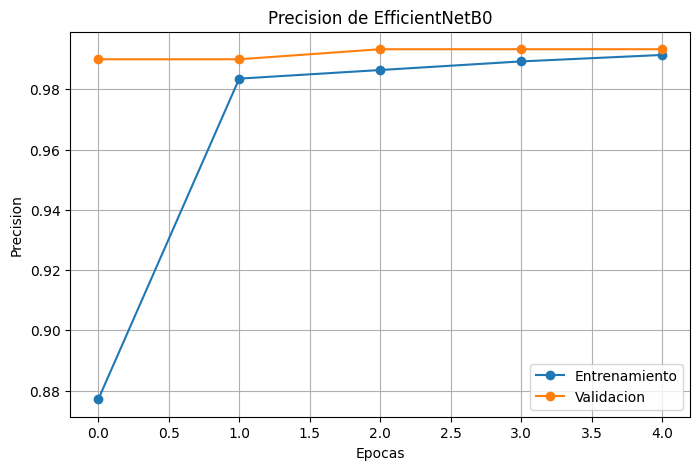

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    historial.history["accuracy"],
    label="Entrenamiento",
    marker="o"
)

plt.plot(
    historial.history["val_accuracy"],
    label="Validacion",
    marker="o"
)

plt.title("Precision de EfficientNetB0")
plt.xlabel("Epocas")
plt.ylabel("Precision")
plt.legend()
plt.grid(True)

plt.savefig("grafica_precision.png", dpi=150)
plt.show()


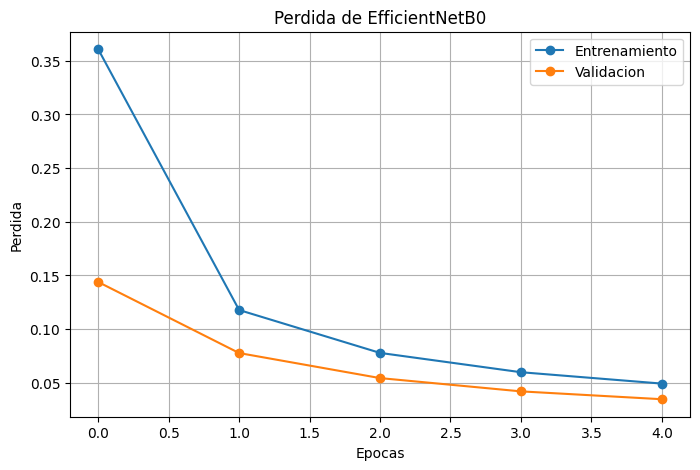

In [12]:

plt.figure(figsize=(8, 5))

plt.plot(
    historial.history["loss"],
    label="Entrenamiento",
    marker="o"
)

plt.plot(
    historial.history["val_loss"],
    label="Validacion",
    marker="o"
)

plt.title("Perdida de EfficientNetB0")
plt.xlabel("Epocas")
plt.ylabel("Perdida")
plt.legend()
plt.grid(True)

plt.savefig("grafica_perdida.png", dpi=150)
plt.show()


10/10 ━━━━━━━━━━━━━━━━━━━━ 20s 1s/step


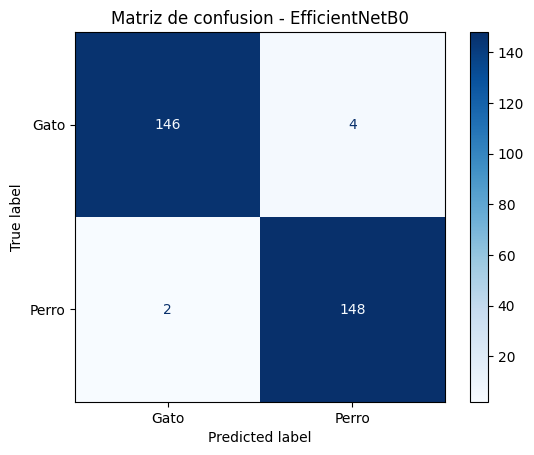

              precision    recall  f1-score   support

        Gato       0.99      0.97      0.98       150
       Perro       0.97      0.99      0.98       150

    accuracy                           0.98       300
   macro avg       0.98      0.98      0.98       300
weighted avg       0.98      0.98      0.98       300



In [13]:

import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Obtener las etiquetas reales
etiquetas_reales = np.concatenate([
    y.numpy() for x, y in test
])

# Obtener las predicciones del modelo
probabilidades = modelo.predict(test).ravel()

predicciones = (
    probabilidades >= 0.5
).astype(int)

# Crear matriz de confusion
matriz = confusion_matrix(
    etiquetas_reales,
    predicciones,
    labels=[0, 1]
)

visualizacion = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Gato", "Perro"]
)

visualizacion.plot(cmap="Blues")
plt.title("Matriz de confusion - EfficientNetB0")
plt.savefig("matriz_confusion.png", dpi=150)
plt.show()

print(classification_report(
    etiquetas_reales,
    predicciones,
    target_names=["Gato", "Perro"]
))


Saving Conoce-las-razas-de-gatos.png to Conoce-las-razas-de-gatos (2).png


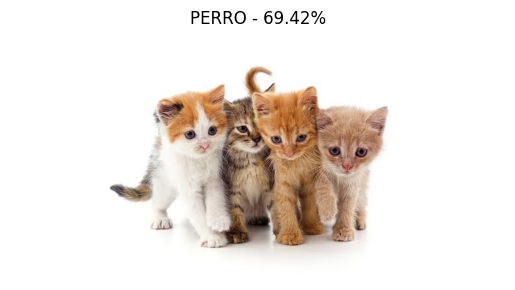

Animal detectado: PERRO
Confianza: 69.42%


In [30]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import io

# Subir una imagen
archivos = files.upload()

for nombre, contenido in archivos.items():

    # Abrir imagen
    imagen = Image.open(
        io.BytesIO(contenido)
    ).convert("RGB")

    # Ajustar tamaño
    imagen_modelo = imagen.resize((224, 224))

    # Convertir a numeros
    arreglo = np.array(
        imagen_modelo, dtype=np.float32
    )

    arreglo = np.expand_dims(arreglo, axis=0)

    # Realizar prediccion
    probabilidad = float(
        modelo.predict(arreglo, verbose=0)[0][0]
    )

    if probabilidad >= 0.5:
        resultado = "PERRO"
        confianza = probabilidad * 100
    else:
        resultado = "GATO"
        confianza = (1 - probabilidad) * 100

    # Mostrar resultado
    plt.imshow(imagen)
    plt.axis("off")
    plt.title(
        f"{resultado} - {confianza:.2f}%"
    )
    plt.show()

    print("Animal detectado:", resultado)
    print(f"Confianza: {confianza:.2f}%")


In [31]:

# Guardar modelo
modelo.save("EfficientNet_Perros_Gatos.keras")

print("Modelo guardado correctamente")


Modelo guardado correctamente


In [32]:

from google.colab import files

files.download("EfficientNet_Perros_Gatos.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>